In [1]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

os.makedirs("results", exist_ok=True)

In [2]:
expression = pd.read_csv("../assignment3/shared_expression_log2.csv", index_col=0)
meta = pd.read_csv("../assignment3/shared_sample_metadata.csv", index_col=0)
kmeans = pd.read_csv("../assignment3/results/kmeans_cluster_assignments.csv", index_col=0)
hier = pd.read_csv("../assignment3/results/hier_cluster_assignments.csv", index_col=0)
gmm = pd.read_csv("../assignment3/results/gmm_cluster_assignments.csv", index_col=0)

assert expression.index.equals(meta.index)
assert expression.index.equals(kmeans.index)
assert expression.index.equals(hier.index)
assert expression.index.equals(gmm.index)
X = expression[expression.var().nlargest(5000).index]
print(X.shape)

(32, 5000)


In [3]:
targets = {
    "condition": (meta["condition"] == "flight").astype(int),
    "kmeans_k2": (kmeans["kmeans_k2"] == sorted(kmeans["kmeans_k2"].unique())[1]).astype(int),
    "hier_k3": hier["hier_k3"],
    "gmm_k2": (gmm["gmm_k_2"] == sorted(gmm["gmm_k_2"].unique())[1]).astype(int)
}

model_targets = [
    ("logreg", "condition"), ("logreg", "kmeans_k2"),
    ("nb", "condition"), ("nb", "hier_k3"),
    ("svm", "condition"), ("svm", "gmm_k2")
]

In [4]:
signatures = []
for method, target in model_targets:
    y = targets[target]
    if method == "logreg":
        model = make_pipeline(StandardScaler(), LogisticRegression(solver="liblinear", max_iter=5000))
        model.fit(X, y)
        importance = abs(model[-1].coef_).max(axis=0)
    elif method == "svm":
        model = make_pipeline(StandardScaler(), SVC(kernel="linear"))
        model.fit(X, y)
        importance = abs(model[-1].coef_).max(axis=0)
    else:
        model = GaussianNB().fit(X, y)
        importance = (model.theta_.max(axis=0) - model.theta_.min(axis=0)) / np.sqrt(model.var_.mean(axis=0) + 1e-8)
    top = pd.Series(importance, index=X.columns).nlargest(20)
    signatures.append(pd.DataFrame({"model": method, "target": target, "gene": top.index, "score": top.values}))

signature_table = pd.concat(signatures, ignore_index=True)
signature_table.to_csv("results/q5_signature_genes.csv", index=False)
genes = signature_table["gene"].drop_duplicates().tolist()
print("Unique signature genes:", len(genes))

Unique signature genes: 88


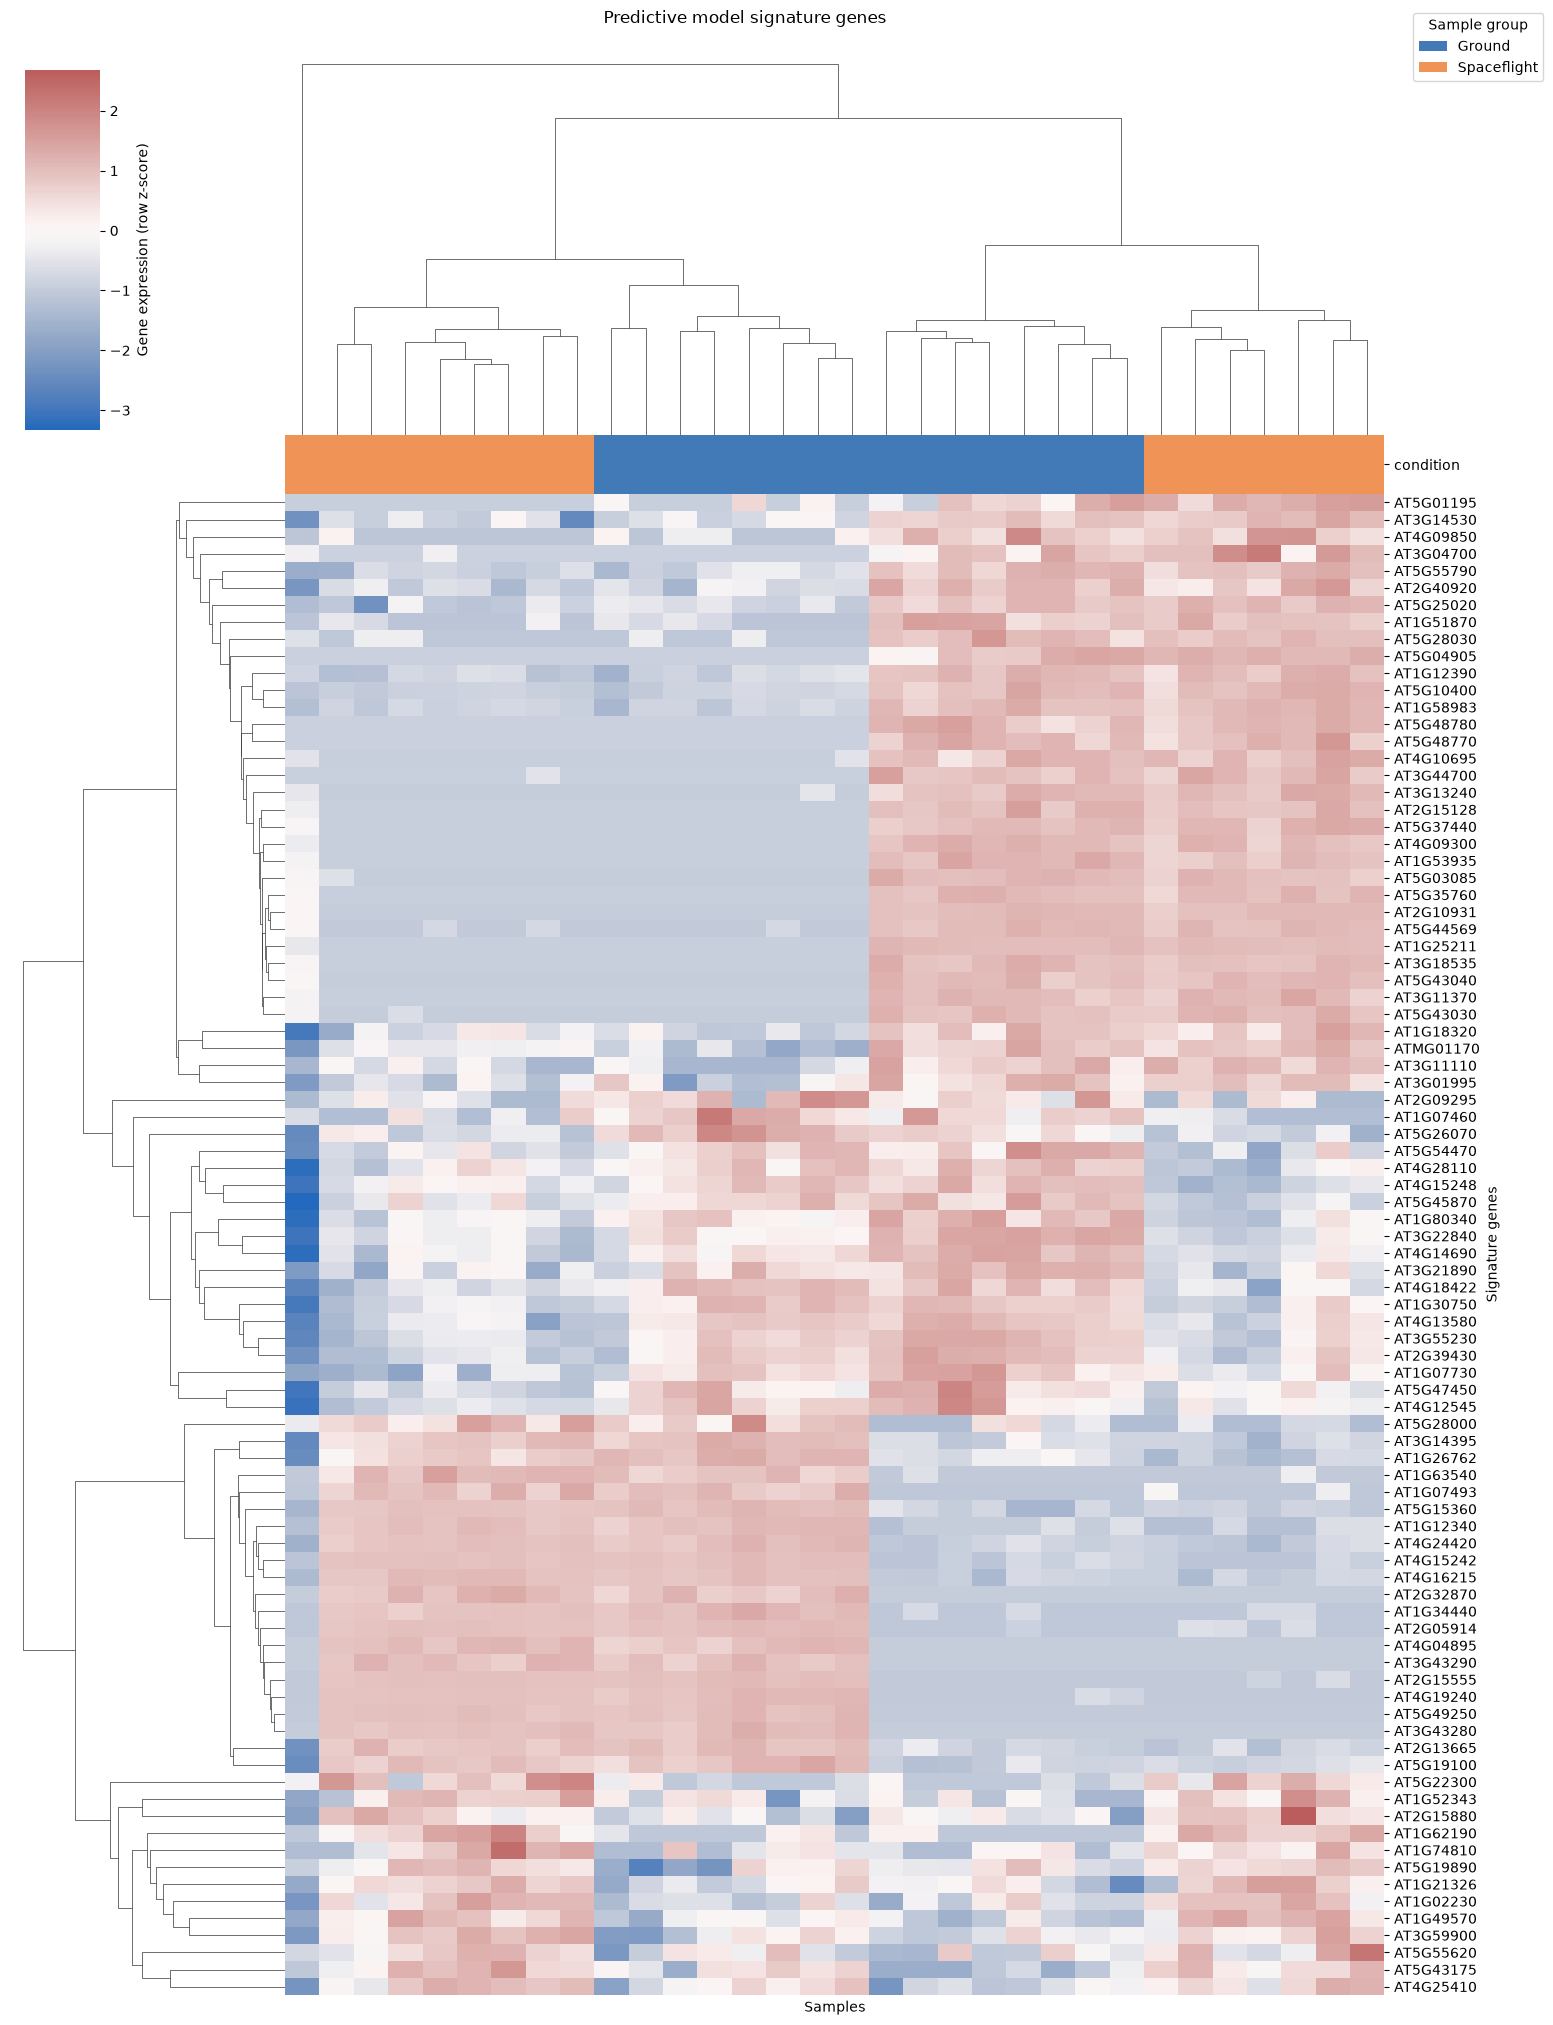

In [5]:
colors = {"ground": "#427ab7", "flight": "#ef9356"}
sample_colors = meta["condition"].map(colors)
heatmap = X[genes].T

plot = sns.clustermap(
    heatmap, z_score=0, method="average", metric="euclidean",
    cmap="vlag", center=0, col_colors=sample_colors,
    row_cluster=True, col_cluster=True,
    xticklabels=False, yticklabels=True, figsize=(15, 20),
    cbar_kws={"label": "Gene expression (row z-score)"}
)
plot.ax_heatmap.set_xlabel("Samples")
plot.ax_heatmap.set_ylabel("Signature genes")
plot.ax_col_dendrogram.legend(
    handles=[Patch(facecolor=colors["ground"], label="Ground"), Patch(facecolor=colors["flight"], label="Spaceflight")],
    title="Sample group", loc="upper left", bbox_to_anchor=(1.02, 1.1)
)
plot.fig.suptitle("Predictive model signature genes", y=1.01)
plot.savefig("results/q5_signature_heatmap.png", dpi=250, bbox_inches="tight")
plt.show()